# Week 4 Lab 1 — CFD Data Production and Qualification

<!-- FLOWMLLAB_COLAB_LAUNCH_V1 -->
[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Ehsan-Roohi/FlowMLLab/blob/main/notebooks/week04/W4_Lab1_CFD_Data_Production_Student.ipynb)

**Runtime:** CPU. **Estimated time:** 20–40 min including interpretation.  
This lab converts the Week-1 educational cavity solver into a controlled data generator. A completed run is a candidate field, not automatically an accepted label.


## Aim and route through this lab

**Aim.** Produce a numerical cavity field that another student can inspect and
qualify before using it as a learning label. The input is Reynolds number and a
declared grid/time-step policy; the output is the velocity, streamfunction and
vorticity together with convergence history and a quality card. This lab runs
the CFD solver. It does not train a network.

The solver advances the vorticity transport equation, solves the streamfunction
Poisson equation, obtains velocity by differentiating streamfunction, and
reapplies the moving-lid and stationary-wall conditions. A small change between
iterations is only one check: it does not establish mesh independence or
accuracy against Ghia. The fixed number of Poisson iterations is also part of
the numerical policy, not an exact Poisson solve.

| Stage | What you do | Visible evidence and interpretation |
|---|---|---|
| Common reproduction | Run the declared Re=100 case | Speed, streamlines, signed streamfunction and vorticity show the physical flow; the residual shows iteration history. |
| Independent check | Compare both centreline components at the printed Ghia positions | Signed discrepancies reveal where the CFD differs; flagged printed entries remain visible. |
| Assigned production | Change only the assigned ID and solve its specified Re | Compare vortex position/strength and check the quality card before export. |
| Export and report | Save fields plus metadata | A saved file is not accepted merely because a solver stopped. Quote each gate and keep grid/time studies separate. |

**Reading.** Use the Lab 1 section of [Lecture 4](../../lectures/week04_cavity_surrogates_deeponet.pdf).
**Output contract.** Each live solve produces a physical-field figure and a
separate solver/reference diagnostic figure. Legends sit outside the data;
all native extrema are retained. Vorticity uses a symmetric-log scale because
wall values are much larger than the weak interior circulation. Its scale is
labelled explicitly; velocity discrepancies remain linear. Ghia supplies
velocity profiles, not a full reference pressure or vorticity field.


## Learning outcomes

- reproduce the common Re=100 benchmark;
- distinguish residual convergence from grid convergence;
- generate one assigned field using a fixed class protocol;
- export an NPZ field and a JSON quality card.


In [1]:
# FLOWMLLAB_COLAB_BOOTSTRAP_V1
# In Colab this cell obtains the complete repository and installs the tested package.
# In a local checkout it leaves the active environment and working directory unchanged.
from pathlib import Path as _FlowMLLabPath
import os as _flowmllab_os
import subprocess as _flowmllab_subprocess
import sys as _flowmllab_sys

if "google.colab" in _flowmllab_sys.modules or _flowmllab_os.environ.get("COLAB_RELEASE_TAG"):
    _flowmllab_root = _FlowMLLabPath("/content/FlowMLLab")
    if not (_flowmllab_root / ".git").is_dir():
        _flowmllab_subprocess.run(
            [
                "git", "clone", "--depth", "1",
                "https://github.com/Ehsan-Roohi/FlowMLLab.git", str(_flowmllab_root),
            ],
            check=True,
        )
    _flowmllab_subprocess.run(
        [
            _flowmllab_sys.executable, "-m", "pip", "install", "-q", "-e",
            f"{_flowmllab_root}[test]",
        ],
        check=True,
    )
    _flowmllab_notebook_dir = _flowmllab_root / "notebooks/week04"
    _flowmllab_os.chdir(_flowmllab_notebook_dir)
    for _flowmllab_path in (_flowmllab_root, _flowmllab_notebook_dir):
        if str(_flowmllab_path) not in _flowmllab_sys.path:
            _flowmllab_sys.path.insert(0, str(_flowmllab_path))
    print("FlowMLLab ready:", _flowmllab_root)

import json, platform, time
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

from cavity_project_utils import (CASE_MAP, GHIA, run_cavity, centerline_profiles,
                                  quality_gate, save_case)

STUDENT_ID = 1       # change to your assigned ID: 1,...,11
STUDENT_NAME = "Your Name"
assert STUDENT_ID in CASE_MAP
print(STUDENT_NAME, CASE_MAP[STUDENT_ID])
print("Python:", platform.python_version())


# Shared, array-driven figures; student outputs stay separate from frozen evidence.
from pathlib import Path
import os, sys
_w4_root = next(p for p in [Path.cwd(), *Path.cwd().parents, Path('/content/FlowMLLab')]
                if (p/'flowmllab/week04_teaching_plots.py').is_file())
if str(_w4_root) not in sys.path: sys.path.insert(0, str(_w4_root))
from flowmllab import week04_teaching_plots as w4plots
W4_OUTPUT = Path(os.environ.get('FLOWMLLAB_W4_OUTPUT', str(_w4_root/'student_outputs/week04_current')))
W4_OUTPUT.mkdir(parents=True, exist_ok=True)
def save_current_figure(fig, name):
    fig.savefig(W4_OUTPUT/(name+'.png'), dpi=150, bbox_inches='tight')
    return fig


Your Name {'Re': 100, 'split': 'train'}
Python: 3.12.14


## Part 1 — Common Re=100 reproduction


In [2]:
t0=time.time()
reproduction = run_cavity(Re=100, N=65, dt=1e-3, max_steps=12000,
                          poisson_iters=60, check_every=250,
                          min_steps=8000, tol=2e-6)
print(f"elapsed: {time.time()-t0:.1f} s")
gate100 = quality_gate(reproduction)
print(json.dumps(gate100, indent=2))


step     250 | residual 7.876e-04


step     500 | residual 3.394e-04


step     750 | residual 2.047e-04


step    1000 | residual 1.417e-04


step    1250 | residual 1.054e-04


step    1500 | residual 8.181e-05


... (24 outputs left out)

step    7750 | residual 2.028e-06


step    8000 | residual 1.773e-06


step    8250 | residual 1.549e-06


step    8500 | residual 1.354e-06
elapsed: 29.3 s
{
  "accepted": true,
  "checks": {
    "finite_fields": true,
    "residual_below_limit": true,
    "reasonable_speed": true,
    "Ghia_Eu": true,
    "Ghia_Ev": true
  },
  "metrics": {
    "div_l2": 2.178692249040144e-16,
    "div_linf": 3.552713678800501e-15,
    "vortex_x": 0.609375,
    "vortex_y": 0.734375,
    "psi_min": -0.10231854748571349,
    "speed_max": 1.0,
    "ghia_Eu": 0.004471302567228937,
    "ghia_Ev": 0.01532524919744962,
    "ghia_Eu_published": 0.004471302567228937,
    "ghia_Ev_published": 0.01532524919744962
  }
}


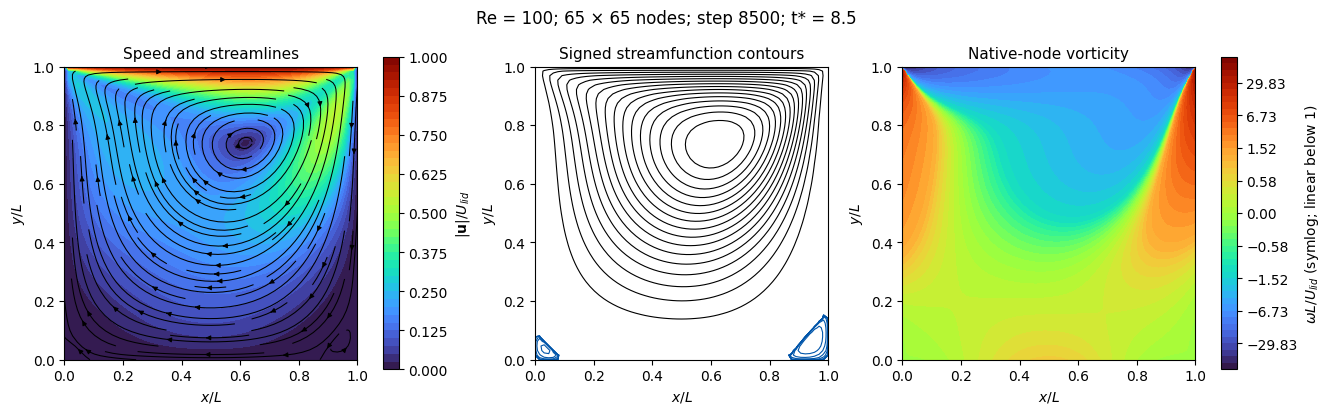

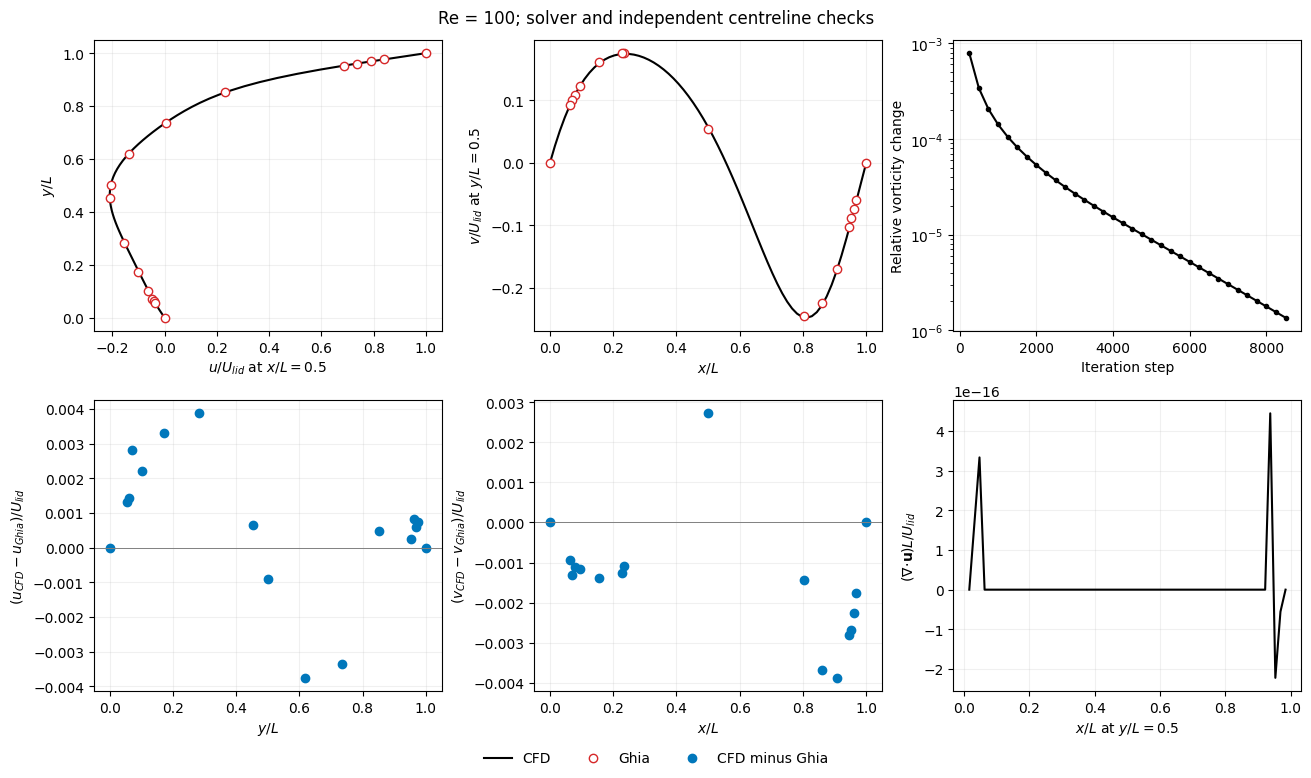

(<Figure size 1320x410 with 5 Axes>, <Figure size 1300x770 with 6 Axes>)

In [3]:
def diagnostic_figure(result, label="reproduction"):
    figures = w4plots.cfd_diagnostics(result)
    for suffix, fig in zip(('fields', 'diagnostics'), figures):
        save_current_figure(fig, f"lab1_{label}_Re{int(result['Re'])}_{suffix}")
        plt.show()
        plt.close(fig)
    return figures

diagnostic_figure(reproduction)


In [4]:
reproduction_path, card100 = save_case(reproduction, STUDENT_ID, "reproduction", W4_OUTPUT/"lab1_reproduction")
print("saved", reproduction_path)


saved D:\ChatGPT Backup\Projects\FlowMLLab\Teaching_Current\repo\results\week04_teaching_outputs\lab1_reproduction\cavity_Re0100_N065_student01.npz


### Checkpoint 1

Record $E_u$, $E_v$, the final residual, $(x_v,y_v)$, and $\psi_{min}$. Explain whether the residual is still decreasing, has plateaued, or satisfies the stopping rule. Do not proceed if fields contain non-finite values.


## Part 2 — Assigned production case


step     250 | residual 7.876e-04


step     500 | residual 3.394e-04


step     750 | residual 2.047e-04


step    1000 | residual 1.417e-04


step    1250 | residual 1.054e-04


step    1500 | residual 8.181e-05


... (24 outputs left out)

step    7750 | residual 2.028e-06


step    8000 | residual 1.773e-06


step    8250 | residual 1.549e-06


step    8500 | residual 1.354e-06
elapsed: 63.0 s
{
  "accepted": true,
  "checks": {
    "finite_fields": true,
    "residual_below_limit": true,
    "reasonable_speed": true,
    "Ghia_Eu": true,
    "Ghia_Ev": true
  },
  "metrics": {
    "div_l2": 2.178692249040144e-16,
    "div_linf": 3.552713678800501e-15,
    "vortex_x": 0.609375,
    "vortex_y": 0.734375,
    "psi_min": -0.10231854748571349,
    "speed_max": 1.0,
    "ghia_Eu": 0.004471302567228937,
    "ghia_Ev": 0.01532524919744962,
    "ghia_Eu_published": 0.004471302567228937,
    "ghia_Ev_published": 0.01532524919744962
  }
}


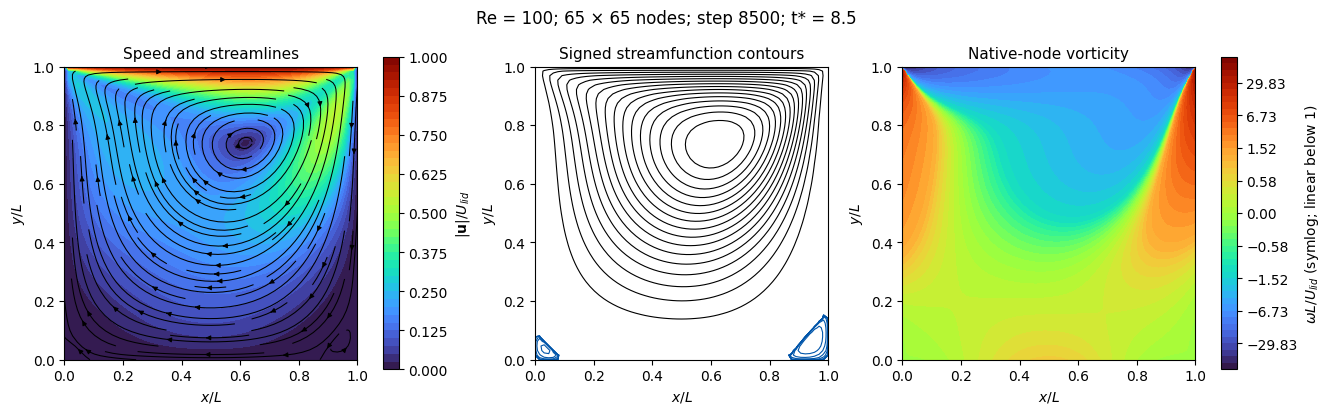

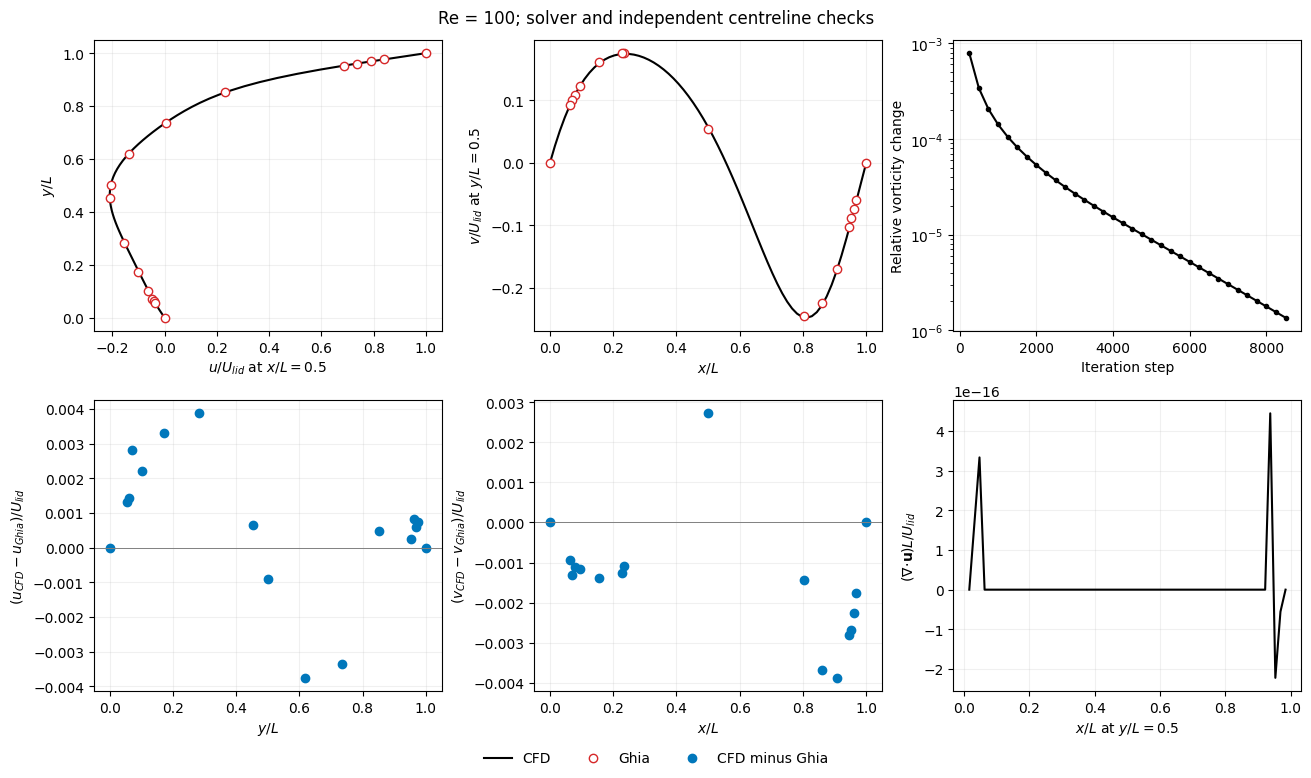

(<Figure size 1320x410 with 5 Axes>, <Figure size 1300x770 with 6 Axes>)

In [5]:
cfg=CASE_MAP[STUDENT_ID]
t0=time.time()
production = run_cavity(Re=cfg["Re"], N=65, dt=1e-3, max_steps=20000,
                        poisson_iters=60, check_every=250,
                        min_steps=8000, tol=1e-5)
print(f"elapsed: {time.time()-t0:.1f} s")
gate=quality_gate(production)
print(json.dumps(gate,indent=2))
diagnostic_figure(production, "production")


In [6]:
production_path, production_card = save_case(
    production, STUDENT_ID, cfg["split"], W4_OUTPUT/"lab1_production")
print("Submit:",production_path)
print("Submit:",production_path.with_name(production_path.stem+"_quality.json"))


Submit: D:\ChatGPT Backup\Projects\FlowMLLab\Teaching_Current\repo\results\week04_teaching_outputs\lab1_production\cavity_Re0100_N065_student01.npz
Submit: D:\ChatGPT Backup\Projects\FlowMLLab\Teaching_Current\repo\results\week04_teaching_outputs\lab1_production\cavity_Re0100_N065_student01_quality.json


## Written response

1. Is the field accepted by every quality check? Quote evidence.  
2. Compare vortex strength/location with Re=100.  
3. Distinguish iterative convergence, grid convergence, and ML generalization.  
4. Explain one mechanism by which CFD label error contaminates a surrogate.  
5. If your case is labeled `test`, explain why you may generate and inspect it but may not use it for model design.


## Article-output contract

<!-- MIE690A article-aligned validation v3 -->

**Role:** Foundational or supporting notebook; see ARTICLE_FIGURE_MAP.md for its evidence dependency.

All manuscript-facing figures must be generated from retained numerical/model outputs through the documented notebook or shared helper, saved under `results/`, and accompanied by machine-readable metrics. Do not redraw curves by eye or substitute a screenshot for a solver-to-reference comparison. The complete ownership table and exact output filenames are in [`ARTICLE_FIGURE_MAP.md`](../../ARTICLE_FIGURE_MAP.md).


## Optional continuation: all seven Ghia Reynolds numbers

Continue with [Lab 5: seven-Re CFD coverage and qualification](../week04/W4_Lab5_All_Re_Ghia_Validation.ipynb). [Lab 6](../week04/W4_Lab6_Ghia_Profile_Optimizer_Depth.ipynb) fits Ghia centreline samples with matched optimizer/depth comparisons; [Lab 7](../week04/W4_Lab7_High_Re_CFD_Ghia.ipynb) qualifies our high-Re full fields before [Lab 8](../week04/W4_Lab8_High_Re_Field_DeepONet.ipynb) compares field predictions with interpolation. All seven Ghia Reynolds numbers have retained CFD, with mesh/steady limits reported in the corresponding study. [Profile evidence](../../results/cavity_ghia_allre/README.md) · [Field evidence](../../results/cavity_highre_ghia/README.md).